# P7 / 02: tradable evaluation of rank-space portfolios

Protocol: [`001_claude_p7_rank_space_preregistration.md`](../../discussions/Rank_Space/001_claude_p7_rank_space_preregistration.md), sections 3–4.

**Book.** Rank weights from the close of d are mapped to the stocks holding those ranks at the close of d+1 and earn their returns on d+2. The book is re-mapped every close, with measured costs on the stock-weight changes.

**Reported.**
- The paper's non-tradable rank-space gross, next to the tradable gross.
- Turnover, split into rank (signal) and stock (signal + re-mapping).

**Gates** per window and arm (α = 0.05/2):
- **G1** net bootstrap lower bound > 0;
- **G2** tradable gross beats 1,000 rank-weight permutations;
- **G3** net > 0 at 2× cost.

In [1]:
import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, p1, p6, p7, s04, s05b
from equity_trading.alpaca import ALPACA_VERSION, download_years, session_schedule
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("P7_SYNTHETIC") == "1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
CFG = p7.P7Config()
ARMS = {"RS-paper": "paper", "RS-net": "net"}
CACHE = work_dir() / "results" / ("p7_synthetic" if SYNTHETIC else "p7")
CACHE.mkdir(parents=True, exist_ok=True)
if SYNTHETIC:
    CFG = replace(CFG, n_ranks=80, train_days=300, valid_days=100, first_test="2017-01-03", end="2017-12-29",
                  seeds=(0,), epochs=3, patience=3, n_placebo=50, n_boot=2000)
OUT = ROOT / "notebooks" / "Rank_Space" / ("02_synthetic" if SYNTHETIC else "02")
OUT.mkdir(parents=True, exist_ok=True)
DS = p7.load_dataset(CACHE / f"dataset_p7{p7.P7_VERSION}_K{CFG.n_ranks}.npz")
WINDOWS = {"B 2017-2019": ("2017-01-01", "2019-12-31"), "A 2020-2025": ("2020-01-01", "2025-12-31")}
if SYNTHETIC:
    WINDOWS = {"B 2017H1": ("2017-01-01", "2017-06-30"), "A 2017H2": ("2017-07-01", "2017-12-31")}
ONES = np.ones(DS["ok"].shape)
SCS = {arm: np.load(CACHE / f"scores_{arm}.npz")["scores"] for arm in ARMS}
ROWS = np.flatnonzero(np.isfinite(SCS["RS-paper"]).any(1))
assert np.all(np.diff(ROWS) == 1), "prediction rows must be contiguous"
W = {arm: p6.weights_from_scores(sc, ONES, DS["X"], DS["ok"]) for arm, sc in SCS.items()}
W["OU (rank)"] = p6.weights_from_scores(np.where(np.isfinite(SCS["RS-paper"]), p6.ou_scores(DS["x"]), np.nan), ONES, DS["X"], DS["ok"])
print(f"{len(ROWS)} prediction days, {DS['index'][ROWS[0]].date()} to {DS['index'][ROWS[-1]].date()}")

2259 prediction days, 2017-01-03 to 2025-12-26


## 1. Results by window: tradable gross, net, the paper's rank-space gross, turnover

total_return  sharpe  max_drawdown  days  \
window      strategy  cost                                             
A 2020-2025 OU (rank) 1x          -0.324  -1.780         0.336  1507   
                      2x          -0.503  -3.193         0.507  1507   
            RS-net    1x           0.174   0.252         0.316  1507   
                      2x          -0.049   0.022         0.349  1507   
            RS-paper  1x          -0.013   0.031         0.299  1507   
                      2x          -0.249  -0.410         0.444  1507   
B 2017-2019 OU (rank) 1x          -0.133  -1.329         0.144   752   
                      2x          -0.215  -2.274         0.220   752   
            RS-net    1x           0.038   0.305         0.130   752   
                      2x          -0.033  -0.229         0.175   752   
            RS-paper  1x          -0.048  -0.538         0.109   752   
                      2x          -0.133  -1.579         0.172   752   

                            rank_gross_bps_day (not tradable)  gross_bps_day  \
window      strategy  cost                                                     
A 2020-2025 OU (rank) 1x                              -78.468         -0.524   
                      2x                              -78.468         -0.524   
            RS-net    1x                             -496.479          2.929   
                      2x                             -496.479          2.929   
            RS-paper  1x                             -447.778          1.945   
                      2x                             -447.778          1.945   
B 2017-2019 OU (rank) 1x                               10.911         -0.546   
                      2x                               10.911         -0.546   
            RS-net    1x                                3.083          1.471   
                      2x                                3.083          1.471   
            RS-paper  1x                                7.997          0.599   
                      2x                                7.997          0.599   

                            cost_bps_day  net_bps_day  \
window      strategy  cost                              
A 2020-2025 OU (rank) 1x           2.044       -2.569   
                      2x           4.089       -4.613   
            RS-net    1x           1.397        1.532   
                      2x           2.794        0.135   
            RS-paper  1x           1.817        0.128   
                      2x           3.635       -1.690   
B 2017-2019 OU (rank) 1x           1.326       -1.872   
                      2x           2.651       -3.197   
            RS-net    1x           0.937        0.535   
                      2x           1.873       -0.402   
            RS-paper  1x           1.237       -0.638   
                      2x           2.474       -1.875   

                            rank_sharpe (not tradable)  gross_sharpe  \
window      strategy  cost                                             
A 2020-2025 OU (rank) 1x                        -0.376        -0.363   
                      2x                        -0.376        -0.363   
            RS-net    1x                        -0.398         0.483   
                      2x                        -0.398         0.483   
            RS-paper  1x                        -0.404         0.473   
                      2x                        -0.404         0.473   
B 2017-2019 OU (rank) 1x                         1.891        -0.387   
                      2x                         1.891        -0.387   
            RS-net    1x                         1.353         0.843   
                      2x                         1.353         0.843   
            RS-paper  1x                         2.766         0.506   
                      2x                         2.766         0.506   

                            rank_turnover  stock_turnover  
window      strategy  cost    

name-space reference (P6 network, 1x): {'A 2020-2025': 0.126, 'B 2017-2019': 0.118}


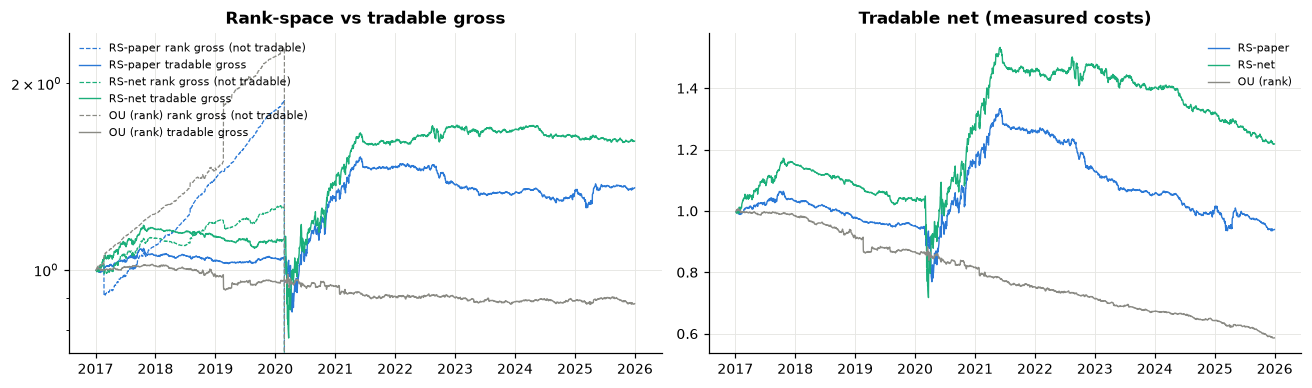

In [2]:
RES, TAB = {}, []
for name, Wm in W.items():
    for cm in (1.0, 2.0):
        RES[(name, cm)] = p7.evaluate(Wm, DS, ROWS, cm)
for (name, cm), df in RES.items():
    for wname, (a, b) in WINDOWS.items():
        x = df.loc[a:b]
        TAB.append({"window": wname, "strategy": name, "cost": f"{cm:g}x", **p6.series_metrics(x["net"]),
                    "rank_gross_bps_day (not tradable)": 1e4 * x.rank_gross.mean(), "gross_bps_day": 1e4 * x.gross.mean(),
                    "cost_bps_day": 1e4 * x.cost.mean(), "net_bps_day": 1e4 * x.net.mean(),
                    "rank_sharpe (not tradable)": np.sqrt(252) * x.rank_gross.mean() / x.rank_gross.std(),
                    "gross_sharpe": np.sqrt(252) * x.gross.mean() / x.gross.std(),
                    "rank_turnover": x.rank_turnover.mean(), "stock_turnover": x.stock_turnover.mean()})
TAB = pd.DataFrame(TAB).set_index(["window", "strategy", "cost"]).sort_index()
TAB.to_csv(OUT / "results.csv", float_format="%.5g"); display(TAB.round(3))
ref = ROOT / "notebooks" / "Deep_Statistical_Arbitrage" / "02" / "summary.json"
if ref.exists() and not SYNTHETIC:
    s6 = json.loads(ref.read_text())["results"]
    print("name-space reference (P6 network, 1x):", {k.split("|")[0]: round(v["sharpe"], 3) for k, v in s6.items() if "|model|1x" in k})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for name, col in zip(W, ("#2a78d6", "#1baf7a", "#8a8a84")):
    r = RES[(name, 1.0)]
    ax[0].plot((1 + r["rank_gross"]).cumprod(), color=col, lw=0.8, ls="--", label=f"{name} rank gross (not tradable)")
    ax[0].plot((1 + r["gross"]).cumprod(), color=col, lw=0.9, label=f"{name} tradable gross")
    ax[1].plot((1 + r["net"]).cumprod(), color=col, lw=0.9, label=name)
ax[0].set_yscale("log"); ax[0].set_title("Rank-space vs tradable gross"); ax[1].set_title("Tradable net (measured costs)")
for a in ax: a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

## 2. Gates (judged arms)

In [ ]:
G, RANKS, BOOT = {}, {}, {}
dates = pd.DatetimeIndex([DS["index"][min(r + 2, len(DS["index"]) - 1)] for r in ROWS])
for arm in ARMS:
    G[arm], RANKS[arm], BOOT[arm] = {}, {}, {}
    r1, r2 = RES[(arm, 1.0)], RES[(arm, 2.0)]
    for wname, (a, b) in WINDOWS.items():
        sel = (dates >= a) & (dates <= b)
        BOOT[arm][wname] = {k: p1.block_bootstrap(r1["net"].loc[a:b].to_numpy(), k, CFG.n_boot, CFG.seed, CFG.alpha) for k in CFG.blocks}
        pg = p6.placebo_gross(W[arm], DS["tret"], DS["ok"], ROWS[sel], CFG.n_placebo, CFG.seed)
        g = r1["gross"].loc[a:b]
        RANKS[arm][wname] = {"total_return": s04.placebo_rank(float(np.prod(1 + g) - 1), np.prod(1 + pg, 1) - 1),
                             "sharpe": s04.placebo_rank(float(np.sqrt(252) * g.mean() / g.std()), np.sqrt(252) * pg.mean(1) / pg.std(1, ddof=1))}
        G[arm][wname] = p7.gates(BOOT[arm][wname], RANKS[arm][wname], p6.series_metrics(r2["net"].loc[a:b]), CFG.alpha)
display(pd.concat({(a, w): pd.DataFrame(v, index=["mean", "lo", "hi"]).T * 1e4 for a, x in BOOT.items() for w, v in x.items()}).round(3))
display(pd.concat({(a, w): pd.DataFrame(v).T for a, x in RANKS.items() for w, v in x.items()}).round(4))
display(pd.concat({a: pd.DataFrame(x) for a, x in G.items()}, axis=1))
YR = pd.DataFrame({n: RES[(n, 1.0)]["net"].groupby(RES[(n, 1.0)].index.year).apply(lambda x: (1 + x).prod() - 1) for n in W})
display((100 * YR).round(2))
both = {arm: all(G[arm][w]["pass"] for w in WINDOWS) for arm in ARMS}
VERDICT = "EDGE_CANDIDATE" if any(both.values()) else "NO_EDGE"
print("arm passes both windows:", both, "| verdict:", VERDICT)
summary = {"study": "P7-02", "synthetic": SYNTHETIC, "config": CFG.as_dict(), "windows": WINDOWS,
           "results": {"|".join(k): v for k, v in TAB.to_dict(orient="index").items()},
           "bootstrap_bps": {a: {w: {str(k): [1e4 * x for x in v] for k, v in b.items()} for w, b in x.items()} for a, x in BOOT.items()},
           "placebo_ranks_gross": RANKS, "gates": G, "arm_passes_both": both,
           "net_by_year": {str(k): v for k, v in YR.to_dict(orient="index").items()}, "verdict": VERDICT,
           "prospective_verdict": "PENDING_2026_HOLDOUT" if VERDICT == "EDGE_CANDIDATE" else "NOT_APPLICABLE",
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "p7": p7.P7_VERSION, "p6": p6.P6_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir())}, indent=2))